## Лабораторная работа №1 | Вариант 5

Выполнил: 

### 1. Numpy

In [11]:
import numpy as np

1. Создайте единичную матрицу размером 3х3

In [28]:
np.eye(3)

array([[1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.]])

2. Создайте кастомный dtype который описывает цвет состоящий из 4х unsigned bytes(RGBA пиксель)

In [262]:
rgba = np.dtype([
    ("R", np.uint8),
    ("G", np.uint8),
    ("B", np.uint8),
    ("A", np.uint8),
])

pixel = np.array([(255, 128, 0, 200)], dtype=rgba)
print(pixel)

[(255, 128, 0, 200)]


3. Как игнорировать все numpy warnings(не рекомендуем к использованию)?

In [263]:
np.seterr(all="ignore")

{'divide': 'ignore', 'over': 'ignore', 'under': 'ignore', 'invalid': 'ignore'}

4. Создайте случайный вектор размера 10 и отсортируйте его

In [264]:
v = np.random.random(10)
print(np.sort(v))

[0.10858275 0.16938798 0.21670338 0.33517105 0.56405437 0.63559658
 0.74661057 0.80463299 0.81193574 0.87671103]


5. Создайте read-only массив(неизменяемый)

In [ ]:
arr = np.arange(10)
arr.setflags(write=False)
print(arr.flags.writeable)

False


6. Рассмотрим случайную матрицу размером 10х2, представляющую декартовы координаты, преобразуем их в полярные координаты

In [314]:
xy = np.random.randn(10, 2)
x, y = xy[:, 0], xy[:, 1]

r = np.hypot(x, y)
phi = np.arctan2(y, x)

polar = np.column_stack([r, phi])
print(polar)

[[ 2.3415295  -1.36668604]
 [ 0.07808369  1.32312039]
 [ 0.74443345  2.41631933]
 [ 1.64705134  0.8713631 ]
 [ 1.84784905 -0.03150097]
 [ 0.24851911  3.13498292]
 [ 1.29916491 -0.12193984]
 [ 0.19414165  0.01761991]
 [ 0.70283103 -2.96524983]
 [ 0.83864345  1.09609536]]


7. Создайте структурированный массив с координатами x и y, охватывающий область [0,1]x[0,1]

In [407]:
N = 10
x_lin = np.linspace(0, 1, N)
y_lin = np.linspace(0, 1, N)
xx, yy = np.meshgrid(x_lin, y_lin)

grid = np.zeros(N * N, dtype=[("x", np.float64), ("y", np.float64)])
grid["x"] = xx.ravel()
grid["y"] = yy.ravel()

print(grid[:12])

[(0.        , 0.        ) (0.11111111, 0.        )
 (0.22222222, 0.        ) (0.33333333, 0.        )
 (0.44444444, 0.        ) (0.55555556, 0.        )
 (0.66666667, 0.        ) (0.77777778, 0.        )
 (0.88888889, 0.        ) (1.        , 0.        )
 (0.        , 0.11111111) (0.11111111, 0.11111111)]


8. Учитывая два массива X и Y, постройте матрицу Коши $C$ ($C_{ij} =\frac{1}{x_i - y_j}$)

In [408]:
x = np.random.normal(size=(5))
y = np.random.normal(size=(5))

C = 1.0 / (x[:, None] - y[None, :])
print(C)

[[-0.91418993  1.13943394  0.49870746  0.57519585  1.19946893]
 [-0.52669898 13.72200154  0.83303451  1.07091013 34.5432728 ]
 [-0.41399634 -2.25231852  1.46291256  2.39852689 -2.04954401]
 [ 1.99542121  0.40442593  0.2777627   0.29998048  0.4117405 ]
 [-0.81414427  1.34551504  0.53454079  0.62339502  1.43003546]]


9. Как конвертировать массив float(32 bit) к массиву целых чисел (integer 32 bit) in place?

In [472]:
a = np.array([1.5, 2.7, 3.9, 4.1], dtype=np.float32)
a = a.astype(np.int32)
print(a, a.dtype)

[1 2 3 4] int32


10. Как случайно заменить p элементов в 2D массиве?

In [612]:
M = np.zeros((5, 5), dtype=int)
p = 5
flat = M.ravel()
id = np.random.choice(flat.size, size=p, replace=False)
flat[id] = -1
print(M)

[[ 0 -1  0 -1  0]
 [ 0  0  0  0  0]
 [ 0  0  0  0  0]
 [ 0  0  0 -1  0]
 [ 0 -1  0 -1  0]]


### 2. Pandas

Найдите ответы на вопросы или выполните действия с предложенным датасетом 

Классический начальный набор данных - данные пассажиров титаника.

Файл: `data.csv`

```
PassangerId - уникальный номер пассажира
Survived - выжил человек или нет
Pclass - класс обслуживания
Name - имя человека, обращение к ней/нему
Sex - пол человека
Age - возраст на момент крушения
SibSp - количество братьев и сестер / супругов на борту "Титаника"
Parch - количество родителей / детей на борту "Титаника"
Ticket - номер билета
Fare - стоимость проезда для пассажиров
Cabin - каюта
Embarked - причал отбытия. C = Cherbourg Q = Queenstown S = Southampton
```

In [613]:
import pandas as pd

In [614]:
df = pd.read_csv("data.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


1. Узнайте сколько было на борту человек

In [615]:
print(f"Всего пассажиров: {len(df)}")

Всего пассажиров: 891


2. Какой медианный и средний возраста пассажиров

In [616]:
print(f"Медианный возраст: {df['Age'].median():.2f}")
print(f"Средний возраст: {df['Age'].mean():.2f}")

Медианный возраст: 28.00
Средний возраст: 29.70


3. Посчитайте процент выживаемости детей(до 16 лет) и взрослых

In [617]:
children = df[df["Age"] < 16]
adults = df[df["Age"] >= 16]

print(f"Дети (<16): выживаемость {children['Survived'].mean():.2%} (n={len(children)})")
print(f"Взрослые: выживаемость {adults['Survived'].mean():.2%} (n={len(adults)})")

Дети (<16): выживаемость 59.04% (n=83)
Взрослые: выживаемость 38.19% (n=631)


4. Верна ли гипотеза, что женщины и дети сажались в шлюпки первыми и выживали больше?

In [618]:
children = df[df["Age"] < 16]
women = df[(df["Sex"] == "female") & (df["Age"] >= 16)]
men = df[(df["Sex"] == "male")   & (df["Age"] >= 16)]

print(f"Дети: {children['Survived'].mean():.2%} (n={len(children)})")
print(f"Женщины:{women['Survived'].mean():.2%} (n={len(women)})")
print(f"Мужчины:{men['Survived'].mean():.2%} (n={len(men)})")

print("Гипотеза верна, процент выживания у детей и женщин значительно более высокий, чем у мужчин")

Дети: 59.04% (n=83)
Женщины:77.52% (n=218)
Мужчины:17.43% (n=413)
Гипотеза верна, процент выживания у детей и женщин значительно более высокий, чем у мужчин


5. Зависит ли выживаемость от класса обслуживания?

In [619]:
surv_by_class = df.groupby("Pclass")["Survived"].mean()
print(surv_by_class * 100)

print("Да, выживаемость зависит от класса - чем выше класс, тем выше процент выживаемости")

Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64
Да, выживаемость зависит от класса - чем выше класс, тем выше процент выживаемости


6. Посчитайте средний возраст умерших женщин и мужчин

In [628]:
dead = df[df["Survived"] == 0]
print(f"Средний возраст умерших женщин: {dead[dead['Sex']=='female']['Age'].mean():.2f}")
print(f"Средний возраст умерших мужчин: {dead[dead['Sex']=='male']['Age'].mean():.2f}")

Средний возраст умерших женщин: 25.05
Средний возраст умерших мужчин: 31.62


7. Различается ли процент выживаемости пассажиров с хотя бы одним родственником на борту и одиночек?

In [629]:
df["HasRelative"] = (df["SibSp"] + df["Parch"]) > 0
surv_by_rel = df.groupby("HasRelative")["Survived"].mean()
print(surv_by_rel * 100)

print("Да, отличается - у пассажиров с родственниками процент выживаемости выше")

HasRelative
False    30.353818
True     50.564972
Name: Survived, dtype: float64
Да, отличается - у пассажиров с родственниками процент выживаемости выше


8. Различается ли средняя стоимость билета у умерших и выживших пассажиров?

In [630]:
print(df.groupby("Survived")["Fare"].mean())

print("Да, различается - у выживших средняя стоимость билета выше")

Survived
0    22.117887
1    48.395408
Name: Fare, dtype: float64
Да, различается - у выживших средняя стоимость билета выше


9. Выведите максимальный и минимальный возраст выживших пассажиров во 2 классе обслуживания

In [631]:
surv_2nd = df[(df["Survived"] == 1) & (df["Pclass"] == 2)]
print(f"Мин. возраст: {surv_2nd['Age'].min()}")
print(f"Макс. возраст: {surv_2nd['Age'].max()}")

Мин. возраст: 0.67
Макс. возраст: 62.0


10. Подтвердите или опровергните гипотезу: молодым мужчинам(от 18 лет) выжить легче, чем более взрослым

In [632]:
men = df[(df["Sex"] == "male") & (df["Age"] >= 18)]
young = men[men["Age"] < 30]
older = men[men["Age"] >= 30]

print(f"18–29 лет: {young['Survived'].mean():.2%} (n={len(young)})")
print(f"30+ лет: {older['Survived'].mean():.2%} (n={len(older)})")

print("Гипотеза неверна, молодые люди выживали реже, чем более взрослые")

18–29 лет: 15.64% (n=179)
30+ лет: 19.44% (n=216)
Гипотеза неверна, молодые люди выживали реже, чем более взрослые


### 3. Визуализация

Используя библиотеки matplotlib/sns/plotly/pandas и набор данных представленный ранее визуализируйте

1. Постройте гистограмму распределения возростов пассажиров

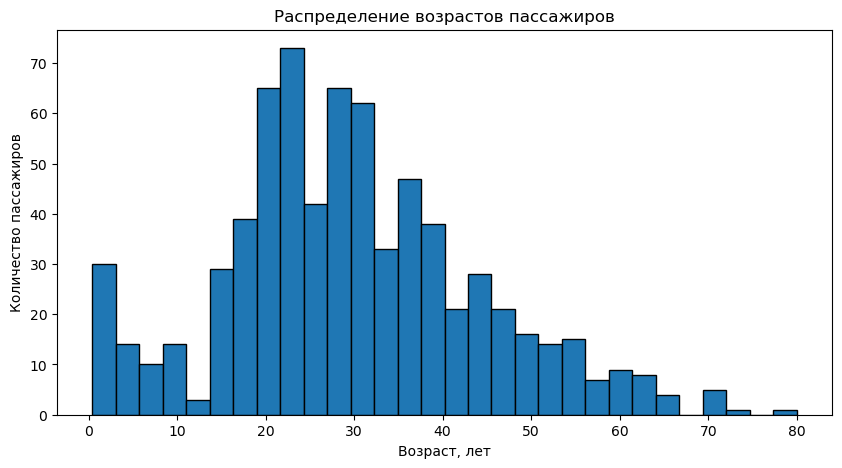

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(df["Age"], bins=30, edgecolor="black")

ax.set_title("Распределение возрастов пассажиров")
ax.set_xlabel("Возраст, лет")
ax.set_ylabel("Количество пассажиров")
plt.show()

2. Постройте гистограммы распределения цен для пассажиров разных классов

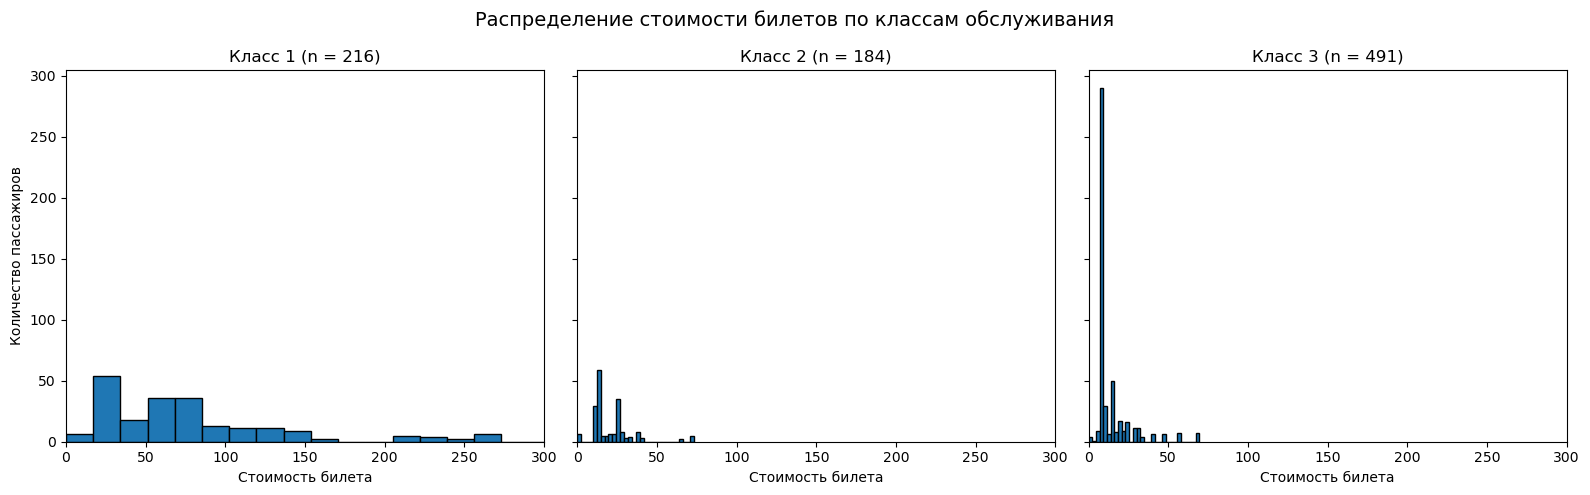

In [752]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for ax, cls in zip(axes, [1, 2, 3]):
    data = df[df["Pclass"] == cls]["Fare"]
    ax.hist(data, bins=30, edgecolor="black")

    ax.set_title(f"Класс {cls} (n = {len(data)})")
    ax.set_xlabel("Стоимость билета")
    ax.set_xlim(0, 300)

axes[0].set_ylabel("Количество пассажиров")
fig.suptitle("Распределение стоимости билетов по классам обслуживания", fontsize=14)
plt.tight_layout()
plt.show()

3. Постройте зависимость цены от возраста пассажира

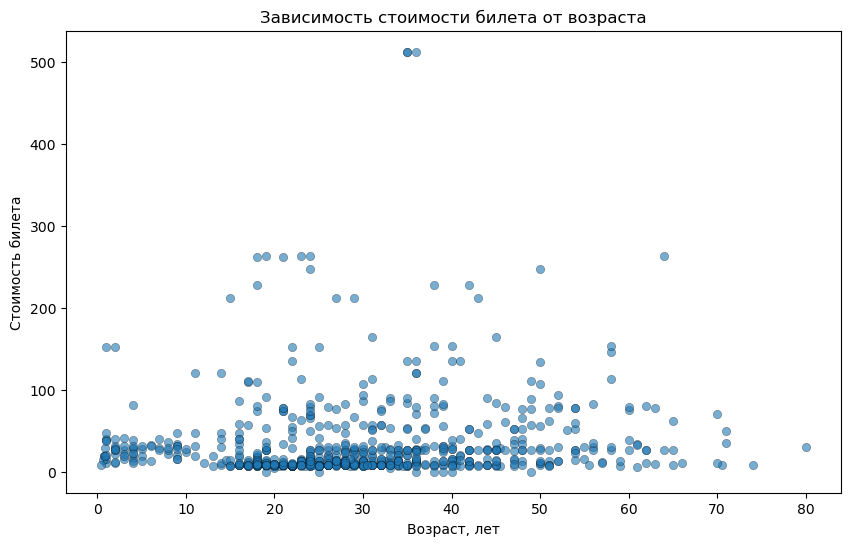

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(df["Age"], df["Fare"], alpha=0.6, edgecolor="black", linewidth=0.3)

ax.set_title("Зависимость стоимости билета от возраста")
ax.set_xlabel("Возраст, лет")
ax.set_ylabel("Стоимость билета")
plt.show()

4. Постройте box plot отображающий распределение цен на билеты в разных классах

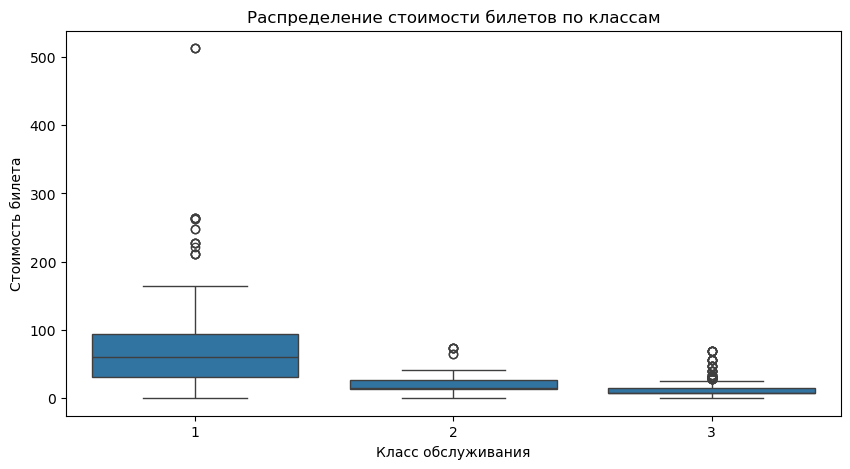

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=df, x="Pclass", y="Fare")

ax.set_title("Распределение стоимости билетов по классам")
ax.set_xlabel("Класс обслуживания")
ax.set_ylabel("Стоимость билета")
plt.show()

5. Визуализируйте распределение долей выживших среди мужчин, женщин и детей(до 16 лет)

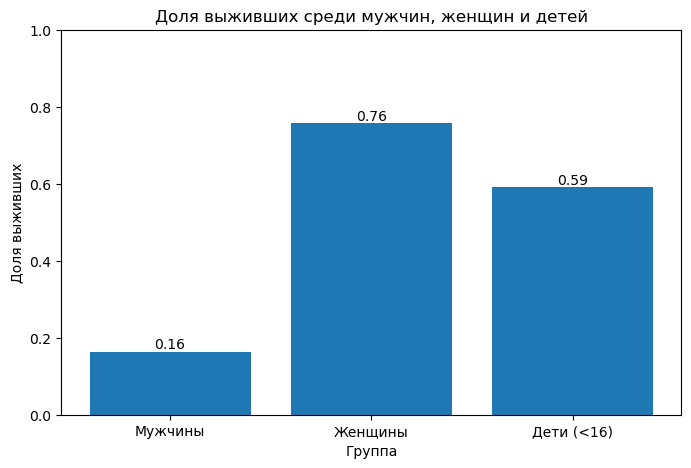

In [869]:
df["Group"] = np.where(
    df["Age"] < 16, "Дети (<16)",
    np.where(df["Sex"] == "female", "Женщины", "Мужчины"),
)

surv = df.groupby("Group")["Survived"].mean().reindex(["Мужчины", "Женщины", "Дети (<16)"])

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(surv.index, surv.values)
plt.bar_label(bars, fmt='%.2f')

ax.set_ylim(0, 1)
ax.set_title("Доля выживших среди мужчин, женщин и детей")
ax.set_xlabel("Группа")
ax.set_ylabel("Доля выживших")
plt.show()

6. Сравните плотности распределения возростов выживших и умерших пассажиров, сделайте выводы

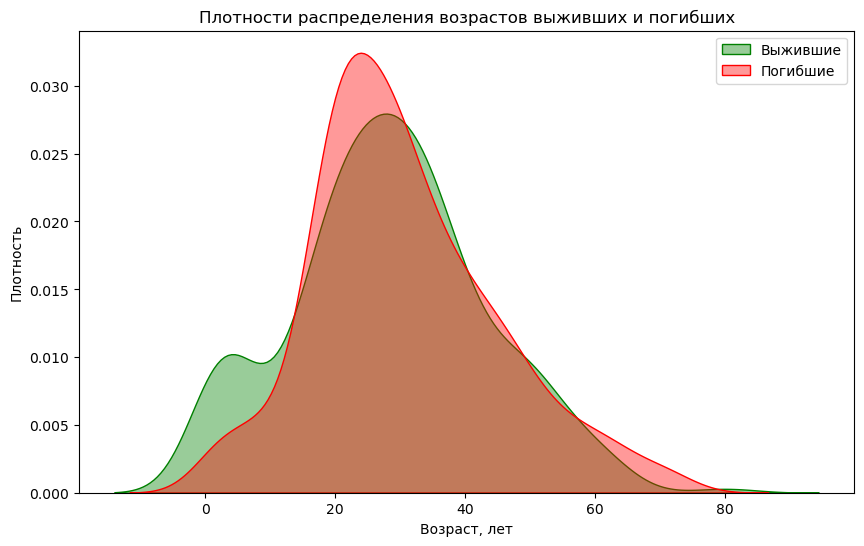

У выживших наблюдается второй пик в районе 0-10 лет(дети), у погибших пик приходится на 20-40 лет(взрослые мужчины) - дети и женщины спасаются первыми


In [876]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.kdeplot(data=df[df["Survived"] == 1], x="Age", label="Выжившие", fill=True, alpha=0.4, color="green")
sns.kdeplot(data=df[df["Survived"] == 0], x="Age", label="Погибшие", fill=True, alpha=0.4, color="red")

ax.set_title("Плотности распределения возрастов выживших и погибших")
ax.set_xlabel("Возраст, лет")
ax.set_ylabel("Плотность")
ax.legend()
plt.show()
print("У выживших наблюдается второй пик в районе 0-10 лет(дети), у погибших пик приходится на 20-40 лет(взрослые мужчины) - дети и женщины спасаются первыми")

7. Постройте круговую диаграмму отображающую выживаемость мужчин и женщин в разных классах обслуживания(визуализация должна быть интуитивно понятная без объяснений, женщины и мужчины соответствующих классов объеденены визуально в одну группу и 2 подгруппы)*

\* Задание на доп. балл

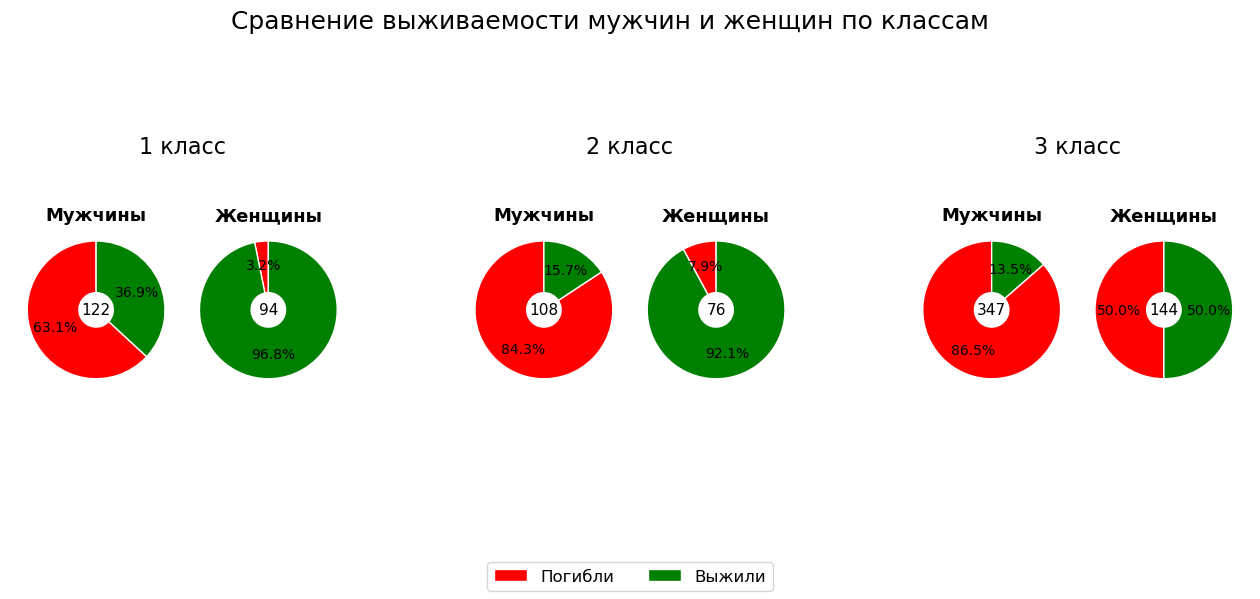

In [906]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(16, 6))
fig.subplots_adjust(bottom=0.15, wspace=0.3)

classes = [1, 2, 3]
col_dead = "red"
col_surv = "green"

legend_wedges = None

for i, pclass in enumerate(classes):
    ax = axes[i]
    sub = df[df["Pclass"] == pclass]
    
    m_sub = sub[sub["Sex"] == "male"]
    m_dead = int((m_sub["Survived"] == 0).sum())
    m_surv = int((m_sub["Survived"] == 1).sum())
    m_total = m_dead + m_surv
    
    w1, _, _ = ax.pie(
        [m_dead, m_surv],
        colors=[col_dead, col_surv],
        autopct="%.1f%%",
        startangle=90,
        pctdistance=0.65,
        center=(-1, 0),
        radius=0.8,
        wedgeprops={"width": 0.6, "edgecolor": "white"}
    )
    
    if i == 0:
        legend_wedges = w1
        
    ax.text(-1, 0, m_total, ha="center", va="center", fontsize=11)
    ax.text(-1, 1.1, "Мужчины", ha="center", va="center", fontsize=13, fontweight="bold")
    
    f_sub = sub[sub["Sex"] == "female"]
    f_dead = int((f_sub["Survived"] == 0).sum())
    f_surv = int((f_sub["Survived"] == 1).sum())
    f_total = f_dead + f_surv
    
    ax.pie(
        [f_dead, f_surv],
        colors=[col_dead, col_surv],
        autopct="%.1f%%",
        startangle=90,
        pctdistance=0.65,
        center=(1, 0),
        radius=0.8,
        wedgeprops={"width": 0.6, "edgecolor": "white"}
    )
    
    ax.text(1, 0, f_total, ha="center", va="center", fontsize=11)
    ax.text(1, 1.1, "Женщины", ha="center", va="center", fontsize=13, fontweight="bold")
    
    ax.set_title(f"{pclass} класс", fontsize=16, pad=20)
    ax.set_xlim(-2, 2)
    ax.set_ylim(-1, 1.5)
    ax.axis('off')

fig.legend(
    handles=legend_wedges, 
    labels=["Погибли", "Выжили"], 
    loc="lower center", 
    ncol=2, 
    fontsize=12, 
    frameon=True
)

fig.suptitle("Сравнение выживаемости мужчин и женщин по классам", fontsize=18, y=0.98)

plt.show()